正在计算 (0,4), (1,4), (1,5), (2,5) 的光子数分布差值并绘制含标注 (a) 的合并折线图...


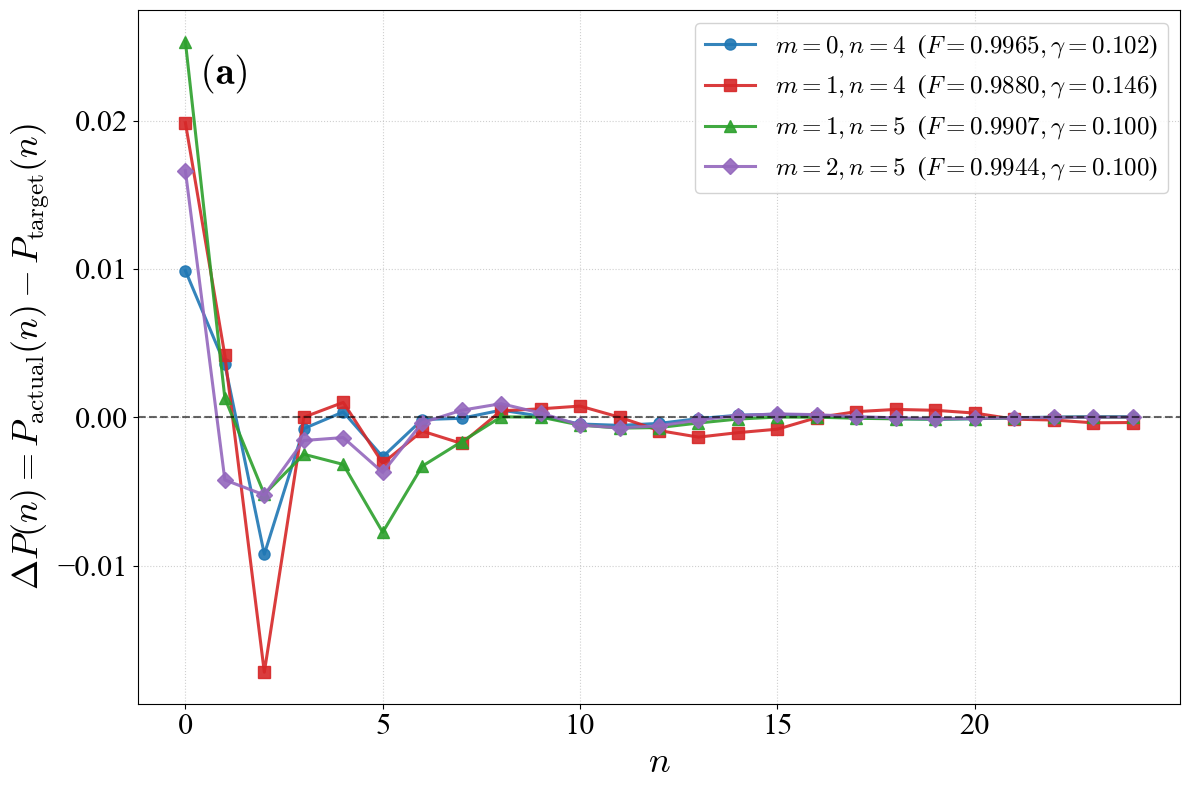

In [9]:
import numpy as np
import math
import qutip as qt
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import warnings
warnings.filterwarnings('ignore')

# ============================================================
#  全局尺寸及字号设置
# ============================================================
FIG_SIZE = (12, 8)               # 单画布尺寸 (宽, 高)
LABEL_SIZE = 26                  # 坐标轴标签大小
TICK_SIZE = 22                   # 坐标轴刻度数字大小
LEGEND_SIZE = 18                 # 图例字号大小
SUBPLOT_LABEL_SIZE = 28          # (a) 角标大小

# ========== 1. 样式配置 ==========
plt.style.use('seaborn-v0_8-muted')
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman'],
    'mathtext.fontset': 'cm'
})

# ========== 2. 核心量子算符与操作 ==========
def displacement_operator(alpha, N_dim):
    """生成位移算符 D(alpha)"""
    a = qt.destroy(N_dim)
    D = (alpha * a.dag() - np.conj(alpha) * a).expm()
    return D

def squeezing_operator(r, phi, N_dim):
    """生成单模压缩算符 S(r, phi)"""
    a = qt.destroy(N_dim)
    S = ((r/2) * (np.exp(-1j*phi) * a * a - np.exp(1j*phi) * a.dag() * a.dag())).expm()
    return S

def apply_gaussian_correction(state, r_corr, beta_corr, phi=0):
    """对态施加高斯修正操作"""
    N_dim = state.shape[0]
    D_beta = displacement_operator(beta_corr, N_dim)
    S_r = squeezing_operator(r_corr, phi, N_dim)
    
    if state.isket:
        return S_r * D_beta * state
    else:
        return S_r * D_beta * state * D_beta.dag() * S_r.dag()

def ideal_cubic_phase_state(gamma, r_ideal, N_dim):
    """
    目标态定义为立方相位算符作用在压缩真空态上
    O = exp(i*gamma*x^3) * S(r_ideal) |0>
    """
    a = qt.destroy(N_dim)
    x = a + a.dag()
    
    S_op = qt.squeeze(N_dim, r_ideal)
    O = (1j * gamma * x**3).expm()
    
    psi = (O * S_op * qt.fock(N_dim, 0)).unit()
    return psi

def generate_single_opa_state(g_val, alpha, m, n, N_dim=50):
    """生成单个 (m,n) 的 OPA 输出态"""
    g = g_val
    G = np.sqrt(1 - 1 / (g**2))
    
    a = qt.destroy(N_dim)
    adag = a.dag()
    
    g_op_diag = [g**(-j) for j in range(N_dim)]
    g_op = qt.Qobj(np.diag(g_op_diag), dims=[[N_dim], [N_dim]])
    
    initial_state = qt.coherent(N_dim, alpha)
    
    psi_out = qt.basis(N_dim, 0) * 0.0
    for k in range(m + 1):
        if n - m + k < 0:
            continue
        num1 = (-1)**(n - m + k)
        den1 = g**(m - k + 1)
        num2 = (G**(n - m + 2 * k)) * math.sqrt(math.factorial(n) * math.factorial(m))
        den2 = math.factorial(k) * math.factorial(n - m + k) * math.factorial(m - k)
        coef = (num1 / den1) * (num2 / den2)
        term_state = coef * (adag**(n - m + k)) * g_op * (a**k) * initial_state
        psi_out += term_state
    
    return psi_out.unit()

def evaluate_fixed_parameters(fixed_params, N_dim=40):
    """根据给定的参数，重新计算保真度"""
    results_dict = {}
    
    for (m, n), params in fixed_params.items():
        psi_raw = generate_single_opa_state(params['g_val'], params['alpha'], m, n, N_dim)
        psi_corrected = apply_gaussian_correction(psi_raw, params['r_corr'], params['beta_corr'])
        psi_ideal = ideal_cubic_phase_state(params['gamma'], params['r_ideal'], N_dim)
        
        fid = qt.fidelity(psi_corrected, psi_ideal)**2
        params['fidelity'] = fid
        results_dict[(m, n)] = params
        
    return results_dict

# ========== 3. 光子数分布与单图对比绘制 ==========
def get_photon_distribution(psi, max_n=30):
    """计算态 |psi> 在 Fock 表象下的光子数分布 P(n) = |<n|psi>|^2"""
    rho = qt.ket2dm(psi) if psi.isket else psi
    p_n = np.real(rho.diag())[:max_n]
    return p_n

def plot_combined_photon_difference(results_dict, selected_pairs, max_n=25, N_dim=40):
    """将四组差值折线绘制在同一张图上，并在左上角标注 (a)"""
    fig, ax = plt.subplots(figsize=FIG_SIZE)
    n_vec = np.arange(max_n)
    
    colors = ['#1f77b4', '#d62728', '#2ca02c', '#9467bd']
    markers = ['o', 's', '^', 'D']
    
    for idx, (m, n) in enumerate(selected_pairs):
        r = results_dict[(m, n)]

        # 1. 计算实际修正态和目标态
        psi_raw = generate_single_opa_state(r['g_val'], r['alpha'], m, n, N_dim)
        psi_corr = apply_gaussian_correction(psi_raw, r['r_corr'], r['beta_corr'])
        psi_ideal = ideal_cubic_phase_state(r['gamma'], r['r_ideal'], N_dim)

        # 2. 计算光子数分布及差值
        p_actual = get_photon_distribution(psi_corr, max_n=max_n)
        p_target = get_photon_distribution(psi_ideal, max_n=max_n)
        delta_p = p_actual - p_target

        # 3. 绘制折线
        label_text = f"$m={m}, n={n}$  ($F={r['fidelity']:.4f}, \\gamma={r['gamma']:.3f}$)"
        ax.plot(n_vec, delta_p, marker=markers[idx], markersize=8, linewidth=2.2, 
                color=colors[idx], label=label_text, alpha=0.9)

    # 绘制参考零线
    ax.axhline(0, color='black', linestyle='--', linewidth=1.5, alpha=0.6)

    # 🌟 添加左上角 (a) 标注（带白色描边增强可读性）
    text_outline = [pe.withStroke(linewidth=3, foreground='white')]
    ax.text(0.06, 0.94, r'$\mathbf{(a)}$', transform=ax.transAxes,
            fontsize=SUBPLOT_LABEL_SIZE, va='top', ha='left',
            path_effects=text_outline, color='black')

    # 坐标轴与排版
    ax.set_xlabel('$n$', fontsize=LABEL_SIZE)
    ax.set_ylabel(r'$\Delta P(n) = P_{\mathrm{actual}}(n) - P_{\mathrm{target}}(n)$', fontsize=LABEL_SIZE)
    ax.set_xticks(np.arange(0, max_n, 2 if max_n <= 20 else 5))
    ax.tick_params(labelsize=TICK_SIZE)
    
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(fontsize=LEGEND_SIZE, loc='best', framealpha=0.85)
    plt.tight_layout()
    plt.show()

# =====================================================================
# 主程序
# =====================================================================
if __name__ == "__main__":
    selected_pairs = [(0, 4), (1, 4), (1, 5), (2, 5)]
    N_DIM_PLOT = 40  
    
    image_params = {
        (0, 4): {'g_val': 1.464, 'gamma': 0.1025, 'r_ideal': -0.0001, 'alpha': 0.0 - 2.145j, 'r_corr': 0.5206, 'beta_corr': 0.0 + 2.963j},
        (1, 4): {'g_val': 1.154, 'gamma': 0.1462, 'r_ideal': -0.0135, 'alpha': 0.0 - 1.448j, 'r_corr': 0.5890, 'beta_corr': 0.0 + 2.493j},
        (1, 5): {'g_val': 1.065, 'gamma': 0.1000, 'r_ideal': -0.0000, 'alpha': 0.0 - 2.260j, 'r_corr': 0.4693, 'beta_corr': 0.0 + 3.401j},
        (2, 5): {'g_val': 1.047, 'gamma': 0.1000, 'r_ideal': -0.0000, 'alpha': 0.0 - 1.614j, 'r_corr': 0.5040, 'beta_corr': 0.0 + 2.703j},
    }
    
    print("=" * 80)
    print("正在计算 (0,4), (1,4), (1,5), (2,5) 的光子数分布差值并绘制含标注 (a) 的合并折线图...")
    print("=" * 80)
    
    # 重新计算保真度并获取结果字典
    final_results = evaluate_fixed_parameters(image_params, N_dim=N_DIM_PLOT)
    
    # 合并绘制 4 条差值折线图
    plot_combined_photon_difference(final_results, selected_pairs, max_n=25, N_dim=N_DIM_PLOT)

正在计算对角组合 (1,1), (2,2), (3,3), (4,4) 的光子数分布差值并绘制折线图...

【参数已修正】：alpha 和 D_corr(beta) 的实部已强制抹除，以下为重新计算的纯虚数保真度
-------------------------------------------------------------------------------------------------------------------
m   | n   | Fidelity | g      | gamma  | r_ideal  | alpha              | r_corr  | D_corr (beta)     
-------------------------------------------------------------------------------------------------------------------
1   | 1   | 0.97517 | 1.083  | 0.1000 | -0.0000   | 0.000-4.136j       | 0.2033  | 0.000+4.406j      
2   | 2   | 0.99270 | 2.059  | 0.1001 | -0.0001   | 0.000-3.676j       | 0.3995  | 0.000+2.786j      
3   | 3   | 0.99180 | 2.338  | 0.1283 | -0.0000   | 0.000-3.933j       | 0.5265  | 0.000+3.020j      
4   | 4   | 0.98744 | 2.473  | 0.1662 | -0.0111   | 0.000-3.960j       | 0.6474  | 0.000+3.258j      



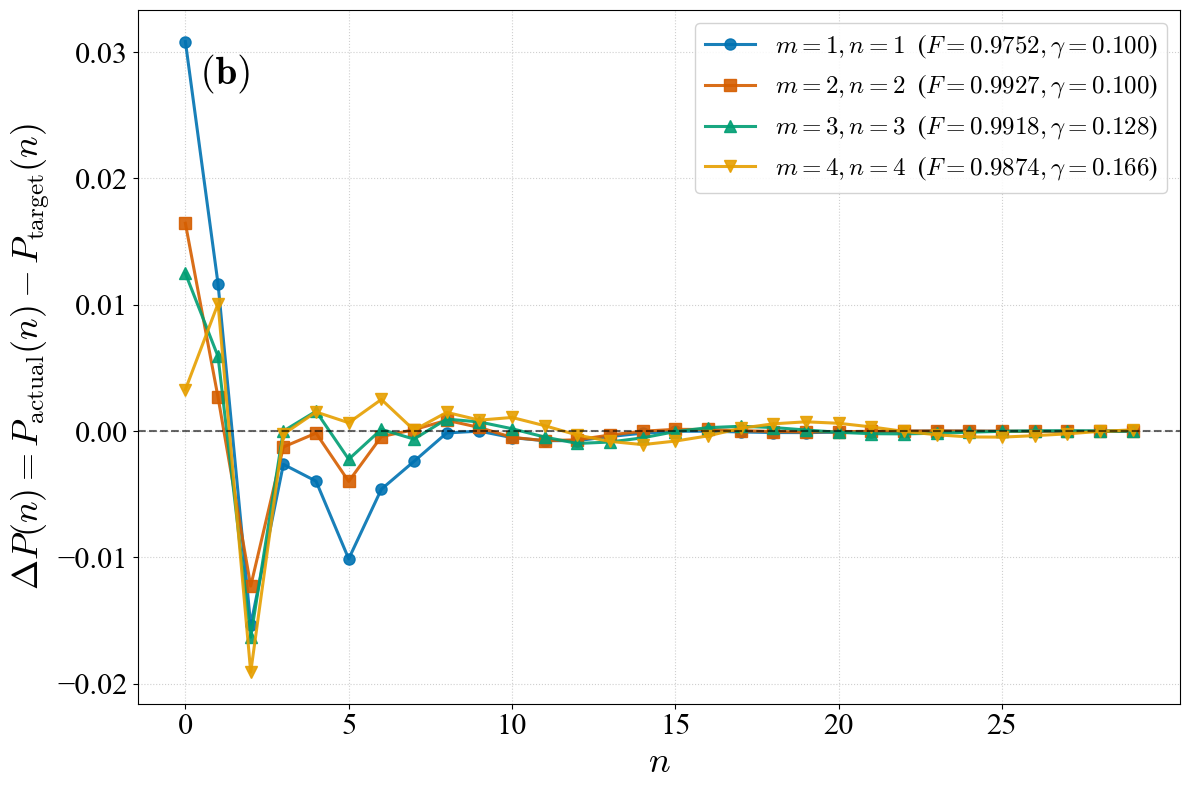

In [11]:
import numpy as np
import math
import qutip as qt
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import warnings
warnings.filterwarnings('ignore')

# ============================================================
#  全局尺寸及字号设置
# ============================================================
FIG_SIZE = (12, 8)               # 单画布物理尺寸 (宽, 高)
LABEL_SIZE = 26                  # 坐标轴标签大小
TICK_SIZE = 22                   # 坐标轴刻度数字大小
LEGEND_SIZE = 18                 # 图例字号大小
SUBPLOT_LABEL_SIZE = 28          # (a) 角标大小

# ========== 1. 样式配置 ==========
plt.style.use('seaborn-v0_8-muted')
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman'],
    'mathtext.fontset': 'cm'
})

# ========== 2. 核心量子算符与操作 ==========
def displacement_operator(alpha, N_dim):
    """生成位移算符 D(alpha)"""
    a = qt.destroy(N_dim)
    D = (alpha * a.dag() - np.conj(alpha) * a).expm()
    return D

def squeezing_operator(r, phi, N_dim):
    """生成单模压缩算符 S(r, phi)"""
    a = qt.destroy(N_dim)
    S = ((r/2) * (np.exp(-1j*phi) * a * a - np.exp(1j*phi) * a.dag() * a.dag())).expm()
    return S

def apply_gaussian_correction(state, r_corr, beta_corr, phi=0):
    """对态施加高斯修正操作"""
    N_dim = state.shape[0]
    D_beta = displacement_operator(beta_corr, N_dim)
    S_r = squeezing_operator(r_corr, phi, N_dim)
    
    if state.isket:
        return S_r * D_beta * state
    else:
        return S_r * D_beta * state * D_beta.dag() * S_r.dag()

def ideal_cubic_phase_state(gamma, r_ideal, N_dim):
    """
    目标态定义为立方相位算符作用在压缩真空态上
    O = exp(i*gamma*x^3) * S(r_ideal) |0>
    """
    a = qt.destroy(N_dim)
    x = a + a.dag()
    
    S_op = qt.squeeze(N_dim, r_ideal)
    O = (1j * gamma * x**3).expm()
    
    psi = (O * S_op * qt.fock(N_dim, 0)).unit()
    return psi

def generate_single_opa_state(g_val, alpha, m, n, N_dim=50):
    """生成单个 (m,n) 的 OPA 输出态"""
    g = g_val
    G = np.sqrt(1 - 1 / (g**2))
    
    a = qt.destroy(N_dim)
    adag = a.dag()
    
    g_op_diag = [g**(-j) for j in range(N_dim)]
    g_op = qt.Qobj(np.diag(g_op_diag), dims=[[N_dim], [N_dim]])
    
    initial_state = qt.coherent(N_dim, alpha)
    
    psi_out = qt.basis(N_dim, 0) * 0.0
    for k in range(m + 1):
        if n - m + k < 0:
            continue
        num1 = (-1)**(n - m + k)
        den1 = g**(m - k + 1)
        num2 = (G**(n - m + 2 * k)) * math.sqrt(math.factorial(n) * math.factorial(m))
        den2 = math.factorial(k) * math.factorial(n - m + k) * math.factorial(m - k)
        coef = (num1 / den1) * (num2 / den2)
        term_state = coef * (adag**(n - m + k)) * g_op * (a**k) * initial_state
        psi_out += term_state
    
    return psi_out.unit()

def evaluate_fixed_parameters(fixed_params, N_dim=40):
    """根据给定的写死参数，重新计算去掉实部后的准确保真度"""
    results_dict = {}
    
    for (m, n), params in fixed_params.items():
        psi_raw = generate_single_opa_state(params['g_val'], params['alpha'], m, n, N_dim)
        psi_corrected = apply_gaussian_correction(psi_raw, params['r_corr'], params['beta_corr'])
        psi_ideal = ideal_cubic_phase_state(params['gamma'], params['r_ideal'], N_dim)
        
        fid = qt.fidelity(psi_corrected, psi_ideal)**2
        params['fidelity'] = fid
        results_dict[(m, n)] = params
        
    return results_dict

# ========== 3. 控制台打印数据汇总 ==========
def print_summary_table(results_dict, selected_pairs):
    """在控制台打印精选组合的优化结果数据表格"""
    print("\n" + "=" * 115)
    print("【参数已修正】：alpha 和 D_corr(beta) 的实部已强制抹除，以下为重新计算的纯虚数保真度")
    print("-" * 115)
    print(f"{'m':<3} | {'n':<3} | {'Fidelity':<8} | {'g':<6} | {'gamma':<6} | {'r_ideal':<8} | {'alpha':<18} | {'r_corr':<7} | {'D_corr (beta)':<18}")
    print("-" * 115)
    
    for (m, n) in selected_pairs:
        r = results_dict[(m, n)]
        alpha_str = f"0.000{np.imag(r['alpha']):+.3f}j"
        disp_str = f"0.000{np.imag(r['beta_corr']):+.3f}j"
        
        print(f"{m:<3} | {n:<3} | {r['fidelity']:.5f} | {r['g_val']:.3f}  | {r['gamma']:.4f} | {r['r_ideal']:.4f}   | {alpha_str:<18} | {r['r_corr']:.4f}  | {disp_str:<18}")
    print("=" * 115 + "\n")

# ========== 4. 光子数分布及差值单图绘制 ==========
def get_photon_distribution(psi, max_n=30):
    """计算态 |psi> 在 Fock 表象下的光子数分布 P(n) = |<n|psi>|^2"""
    rho = qt.ket2dm(psi) if psi.isket else psi
    p_n = np.real(rho.diag())[:max_n]
    return p_n

def plot_combined_photon_difference(results_dict, selected_pairs, max_n=30, N_dim=80):
    """将四组差值折线绘制在同一张图上，采用全新的暖色/高辨识度配色方案并带 (a) 标注"""
    fig, ax = plt.subplots(figsize=FIG_SIZE)
    n_vec = np.arange(max_n)
    
    # 🌟 使用一套全新独立配色方案 (深蓝青、珊瑚橙红、翡翠绿、金琥珀) 与点标记
    colors = ['#0072B2', '#D55E00', '#009E73', '#E69F00']
    markers = ['o', 's', '^', 'v']
    
    for idx, (m, n) in enumerate(selected_pairs):
        r = results_dict[(m, n)]

        # 1. 计算实际修正态和目标态
        psi_raw = generate_single_opa_state(r['g_val'], r['alpha'], m, n, N_dim)
        psi_corr = apply_gaussian_correction(psi_raw, r['r_corr'], r['beta_corr'])
        psi_ideal = ideal_cubic_phase_state(r['gamma'], r['r_ideal'], N_dim)

        # 2. 计算光子数分布及差值
        p_actual = get_photon_distribution(psi_corr, max_n=max_n)
        p_target = get_photon_distribution(psi_ideal, max_n=max_n)
        delta_p = p_actual - p_target

        # 3. 绘制折线
        label_text = f"$m={m}, n={n}$  ($F={r['fidelity']:.4f}, \\gamma={r['gamma']:.3f}$)"
        ax.plot(n_vec, delta_p, marker=markers[idx], markersize=8, linewidth=2.2, 
                color=colors[idx], label=label_text, alpha=0.9)

    # 绘制参考零线
    ax.axhline(0, color='black', linestyle='--', linewidth=1.5, alpha=0.6)

    # 🌟 添加左上角 (a) 标注
    text_outline = [pe.withStroke(linewidth=3, foreground='white')]
    ax.text(0.06, 0.94, r'$\mathbf{(b)}$', transform=ax.transAxes,
            fontsize=SUBPLOT_LABEL_SIZE, va='top', ha='left',
            path_effects=text_outline, color='black')

    # 坐标轴与排版
    ax.set_xlabel('$n$', fontsize=LABEL_SIZE)
    ax.set_ylabel(r'$\Delta P(n) = P_{\mathrm{actual}}(n) - P_{\mathrm{target}}(n)$', fontsize=LABEL_SIZE)
    ax.set_xticks(np.arange(0, max_n, 2 if max_n <= 20 else 5))
    ax.tick_params(labelsize=TICK_SIZE)
    
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(fontsize=LEGEND_SIZE, loc='best', framealpha=0.85)
    plt.tight_layout()
    plt.show()

# =====================================================================
# 主程序
# =====================================================================
if __name__ == "__main__":
    selected_pairs = [(1, 1), (2, 2), (3, 3), (4, 4)]
    N_DIM_PLOT = 80  
    
    image_params = {
        (1, 1): {'g_val': 1.083, 'gamma': 0.1000, 'r_ideal': -0.0000, 'alpha': 0.0 - 4.136j, 'r_corr': 0.2033, 'beta_corr': 0.0 + 4.406j},
        (2, 2): {'g_val': 2.059, 'gamma': 0.1001, 'r_ideal': -0.0001, 'alpha': 0.0 - 3.676j, 'r_corr': 0.3995, 'beta_corr': 0.0 + 2.786j},
        (3, 3): {'g_val': 2.338, 'gamma': 0.1283, 'r_ideal': -0.0000, 'alpha': 0.0 - 3.933j, 'r_corr': 0.5265, 'beta_corr': 0.0 + 3.020j},
        (4, 4): {'g_val': 2.473, 'gamma': 0.1662, 'r_ideal': -0.0111, 'alpha': 0.0 - 3.960j, 'r_corr': 0.6474, 'beta_corr': 0.0 + 3.258j},
    }
    
    print("=" * 80)
    print("正在计算对角组合 (1,1), (2,2), (3,3), (4,4) 的光子数分布差值并绘制折线图...")
    print("=" * 80)
    
    # 重新计算保真度并获取结果字典
    final_results = evaluate_fixed_parameters(image_params, N_dim=N_DIM_PLOT)
    
    # 控制台打印保真度表格
    print_summary_table(final_results, selected_pairs)
    
    # 绘制光子数分布差值图（展示前 30 个光子截断，以适应更高的阶数状态）
    plot_combined_photon_difference(final_results, selected_pairs, max_n=30, N_dim=N_DIM_PLOT)